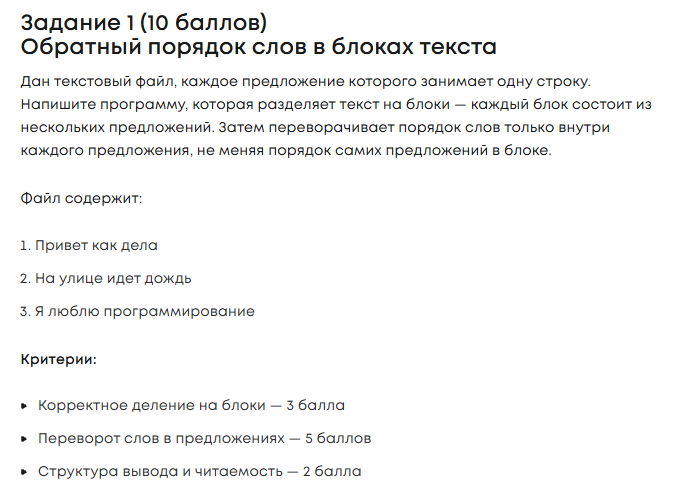

# Выполнение задания №1

In [31]:
# Задаем размер блока (пусть будет по 2 предложения в блоке)
block_size = 2

# Открываем файл
with open('file1.txt', 'r', encoding='utf-8') as file:
    lines = file.readlines()

clean_sentences = []
for line in lines:
    clean_line = line.strip() # убираем пробелы и энтеры по краям
    if clean_line != "":      # если строка не пустая, берём её
        clean_sentences.append(clean_line)

# КРИТЕРИЙ 1: Деление на блоки
# Создаем список, где будут храниться наши блоки
blocks = []
current_block = []

for i in range(len(clean_sentences)):
    current_block.append(clean_sentences[i])

    # Если в текущем блоке набралось нужное количество предложений
    # ИЛИ это вообще последнее предложение в тексте, то сохраняем блок
    if len(current_block) == block_size or i == len(clean_sentences) - 1:
        blocks.append(current_block)
        current_block = [] # обнуляем чтобы собирать следующий блок

# КРИТЕРИЙ 2 и 3: Переворот слов и красивый вывод
# Проходимся по каждому блоку
for block_index in range(len(blocks)):
    print(f"--- Блок {block_index + 1} ---")

    # Достаем предложения из текущего блока
    for sentence in blocks[block_index]:
        # Разбиваем предложение на слова по пробелам
        words = sentence.split()

        # Переворачиваем список слов задом наперёд
        reversed_words = words[::-1]

        # Склеиваем слова обратно в строку через пробел
        new_sentence = " ".join(reversed_words)

        # Выводим результат
        print(new_sentence)

    print() # просто пустая строка, чтобы блоки визуально отделялись

--- Блок 1 ---
дела как Привет 1.
дождь идет улице На 2.

--- Блок 2 ---
программирование люблю Я 3.



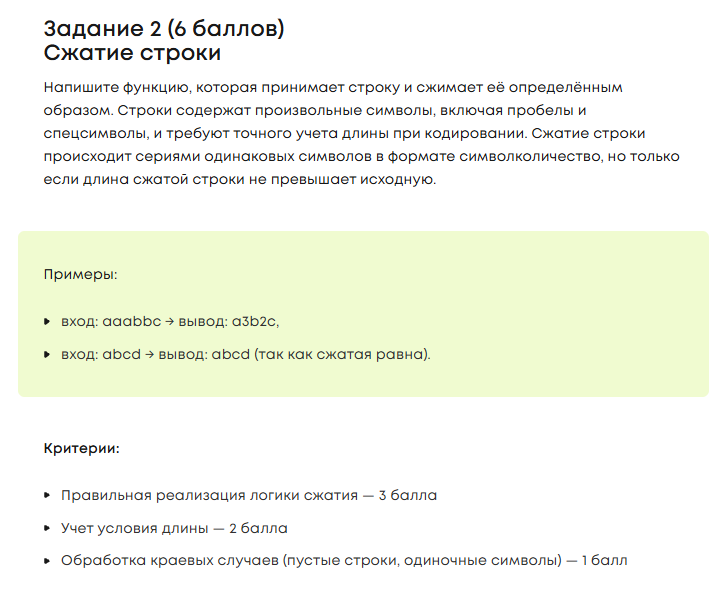

# Выполнение задания №2

In [32]:
def compress_string(text):
    # КРИТЕРИЙ 3: Обработка краевых случаев.
    # Если передали пустую строку, сжимать нечего, сразу возвращаем ее
    if len(text) == 0:
        return ""

    # КРИТЕРИЙ 1: Реализация логики сжатия
    compressed = "" # Сюда будем по кусочкам собирать новую сжатую строку
    count = 1       # Счётчик одинаковых букв. Начинаем с 1, т.к. хотя бы одна буква уже есть

    # Запускаем цикл со второго символа и до конца
    for i in range(1, len(text)):
        # Сравниваем текущую букву с предыдущей
        if text[i] == text[i - 1]:
            count += 1 # Если они одинаковые, просто плюсуем счетчик
        else:
            # Если буква сменилась
            # Записываем в результат предыдущую букву и сколько раз она встретилась
            compressed += text[i - 1] + str(count)
            count = 1 # Сбрасываем счетчик обратно на 1 для новой буквы

    # Когда цикл for заканчивается, самая последняя серия букв не попадает в строку (потому что после нее нет другой буквы, чтобы сработал else).
    # Поэтому добавляем хвост вручную после цикла:
    compressed += text[-1] + str(count)

    # КРИТЕРИЙ 2: Учёт условия длины
    # Проверяем, стала ли строка короче или осталась такой же
    if len(compressed) <= len(text):
        return compressed
    else:
        return text # Если сжатая стала длиннее, возвращаем оригинальную


# Проверка
print(compress_string("aaabbc"))
print(compress_string("abcd"))
print(compress_string(""))
print(compress_string("z"))

a3b2c1
abcd

z


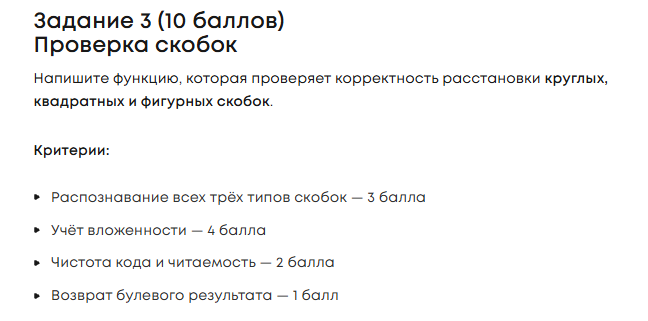

# Выполнение задания №3

In [33]:
def check_brackets(text):
    # Создаем пустой список, он будет работать как стопка для открывающих скобок
    stack = []

    # КРИТЕРИЙ 1: Распознавание всех трёх типов скобок
    # Создаём словарик, где ключ - это закрывающая скобка, а значение - правильная открывающая.
    brackets_map = {')': '(', ']': '[', '}': '{'}

    # Проходимся по каждому символу в строке
    for char in text:
        # Если символ - это открывающая скобка (то есть есть среди значений словаря)
        if char in brackets_map.values():
            stack.append(char) # Кладём её в нашу стопку

        # Если символ - это закрывающая скобка (есть среди ключей)
        elif char in brackets_map.keys():
            # Если мы нашли закрывающую скобку, а стопка пустая (открывающих не было)
            if len(stack) == 0:
                return False # Расстановка уже неправильная

            # КРИТЕРИЙ 2: Учёт вложенности
            # Достаем самую верхнюю (последнюю) скобку из стопки
            top_bracket = stack.pop()

            # Если последняя открывающая не пара нашей закрывающей
            if brackets_map[char] != top_bracket:
                return False

    # КРИТЕРИЙ 4: Возврат булевого результата
    # Если мы прошлись по всему тексту и стопка пустая - значит всем скобкам нашлась пара (True)
    # Если в стопке что-то осталось - значит есть незакрытые скобки (False)
    if len(stack) == 0:
        return True
    else:
        return False

# Проверка
print(check_brackets("()"))           # True
print(check_brackets("()[]{}"))       # True
print(check_brackets("{[()]}"))       # True (вложенность работает)
print(check_brackets("(]"))           # False (не та пара)
print(check_brackets("([)]"))         # False (неправильная вложенность)
print(check_brackets("{[}"))          # False

True
True
True
False
False
False


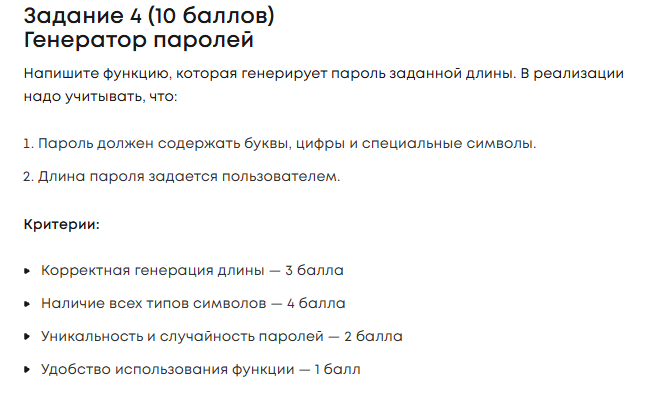

# Выполнение задания №4

In [34]:
import random
import string

# КРИТЕРИЙ 4: Удобство использования
def generate_password(length):
    # Раз нам нужны обязательно буквы(1), цифры(1) и спецсимволы(1), то минимальная длина пароля должна быть 3.
    if length < 3:
        return "Ошибка: длина пароля должна быть минимум 3 символа"

    # Подготавливаем базу символов с помощьюй библиотеки string
    letters = string.ascii_letters  # Все английские буквы (маленькие и большие)
    digits = string.digits          # Цифры от 0 до 9
    symbols = string.punctuation    # Всякие знаки (!, @, #, $ и т.д.)

    # Смешиваем всё в одну большую кучу
    all_chars = letters + digits + symbols

    # КРИТЕРИЙ 2: Наличие всех типов символов
    # Гарантированно берем по одному символу из каждой нужной группы
    password_list = [
        random.choice(letters),
        random.choice(digits),
        random.choice(symbols)
    ]

    # КРИТЕРИЙ 1: Корректная генерация длины
    # Добиваем оставшуюся длину случайными символами из общей кучи
    # Нам нужно добавить (длина минус 3 уже добавленных символа)
    for i in range(length - 3):
        password_list.append(random.choice(all_chars))

    # КРИТЕРИЙ 3: Уникальность и случайность
    # Сейчас пароль всегда начинается с буквы, потом цифра, потом символ.
    # Чтобы кто-то не догадался о паттерне, перемешиваем наш список:
    random.shuffle(password_list)

    # Склеиваем список обратно в единую строку без пробелов
    final_password = "".join(password_list)

    return final_password

# Проверка
print(generate_password(8))
print(generate_password(12))
print(generate_password(30))
print(generate_password(2))
print(generate_password(-1))

!vC{9nGj
F9$W%a?SG3q9
ukm.tx273{yUhdk]Sp5l4`W#PuB6,D
Ошибка: длина пароля должна быть минимум 3 символа
Ошибка: длина пароля должна быть минимум 3 символа


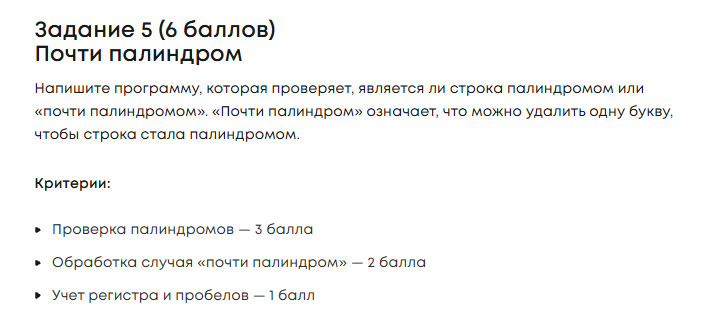

# Выполнение задания №5

In [35]:
def check_almost_palindrome(text):
    # КРИТЕРИЙ 3: Учёт регистра и пробелов
    # Сначала нужно почистить строку. Палиндромы читаются одинаково, не обращая внимания на заглавные буквы и пробелы
    # Поэтому переводим всё в нижний регистр (.lower()) и убираем пробелы (.replace).
    clean_text = text.lower().replace(" ", "")

    # Напишем внутри маленькую вспомогательную функцию чисто для проверки на палиндром.
    def is_palindrome(s):
        # Если строка равна самой себе, перевернутой задом наперед ([::-1]) - это палиндром
        return s == s[::-1]

    # КРИТЕРИЙ 1: Проверка палиндромов (обычных)
    # Если очищенный текст уже является палиндромом, то ничего удалять не надо
    if is_palindrome(clean_text):
        return "Палиндром"

    # КРИТЕРИЙ 2: Обработка случая «почти палиндром»
    # Если слово не палиндром, начинаем по очереди вырезать по одной букве
    for i in range(len(clean_text)):
        # Создаем новую строку без текущей буквы (под индексом i)
        # clean_text[:i] - берем всё ДО этой буквы
        # clean_text[i+1:] - берем всё ПОСЛЕ этой буквы
        # Склеиваем их, и получается слово без одной буквы
        test_string = clean_text[:i] + clean_text[i+1:]

        # Проверяем получившийся обрезок
        if is_palindrome(test_string):
            # Если после удаления одной буквы стал палиндром, значит это "почти палиндром"
            return "Почти палиндром"

    # Если мы перебрали все варианты удаления одной буквы, но палиндром так и не получился:
    return "Обычная строка (не палиндром)"

# Проверка
print(check_almost_palindrome("Радар"))             # "Палиндром"
print(check_almost_palindrome("Около Мити молоко")) # "Палиндром"
print(check_almost_palindrome("радара"))            # "Почти палиндром" (убираем последнюю 'а')
print(check_almost_palindrome("привет"))            # "Обычная строка"
print(check_almost_palindrome("abccbxa"))           # "Почти палиндром" (вот тут убираем 'x' -> 'abccba')

Палиндром
Палиндром
Почти палиндром
Обычная строка (не палиндром)
Почти палиндром


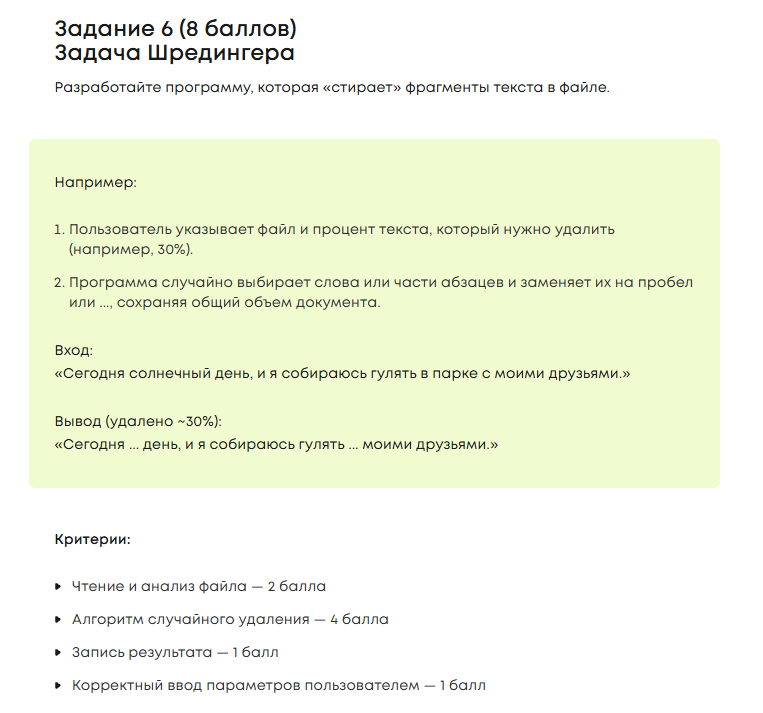

# Выполнение задания №6

In [37]:
import random
import os

def schrodinger_text():
    # КРИТЕРИЙ 4: Корректный ввод параметров пользователем
    print("--- Задача Шредингера ---")
    file_name = input("Введи имя файла (например, text.txt): ")

    # Небольшая проверка, чтобы прога не крашилась, если файла нет
    if not os.path.exists(file_name):
        print("Ошибка: такого файла в папке нет!")
        return

    percent_str = input("Какой процент текста скрыть? (введи число от 1 до 99): ")

    # Проверяем, что ввели именно число, а не буквы
    if not percent_str.isdigit():
        print("Ошибка: нужно было ввести число!")
        return

    percent = int(percent_str)

    # КРИТЕРИЙ 1: Чтение файла и анализ файла
    # Открываем файл и читаем его построчно
    with open(file_name, 'r', encoding='utf-8') as file:
        lines = file.readlines()

    new_lines = [] # Сюда будем складывать уже "дырявый" текст

    # КРИТЕРИЙ 2: Алгоритм случайного удаления
    for line in lines:
        # Разбиваем строку на список отдельных слов
        words = line.split()
        new_words = []

        for word in words:
            # Бросаем виртуальный кубик со 100 гранями
            chance = random.randint(1, 100)

            # Если выпавшее число попало в наш процент - стираем слово
            if chance <= percent:
                new_words.append("...")
            else:
                # Иначе оставляем слово как было
                new_words.append(word)

        # Склеиваем слова обратно в строку через пробел
        new_line = " ".join(new_words)
        new_lines.append(new_line)

    # КРИТЕРИЙ 3: Запись результата
    # Придумываем имя для нового файла
    out_name = "censored_" + file_name

    with open(out_name, 'w', encoding='utf-8') as out_file:
        # Склеиваем все строки через Enter (\n) и записываем разом
        out_file.write("\n".join(new_lines))

    print(f"Готово! Текст был обработан и сохранен в файл: {out_name}")

# Запускаем функцию
schrodinger_text()

--- Задача Шредингера ---
Введи имя файла (например, text.txt): text.txt
Какой процент текста скрыть? (введи число от 1 до 99): 70
Готово! Текст был обработан и сохранен в файл: censored_text.txt
